# Monte Carlo 基础

本 Notebook 只承担四个基础任务：随机数与随机变量、seed 与复现、样本量与重复次数、用大量随机样本逼近期望。

[返回理论正文](../../lectures/monte-carlo.qmd#sec-mc-basics) · [下载 Notebook (ZIP)](../../resources/monte-carlo/downloads/00-monte-carlo-basics.zip)

页面展示交接包已保存的执行结果；渲染不执行代码。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
SEED = 20261001
rng = np.random.default_rng(SEED)

设 \(X\sim N(0,1)\)。一次 draw 只是随机变量的一次实现，大量 draw 才形成可观察的经验分布。

In [2]:
one_draw = rng.normal()
sample_100 = rng.normal(size=100)
sample_10000 = rng.normal(size=10000)
pd.Series({
    "one_draw": one_draw,
    "mean_100": sample_100.mean(),
    "sd_100": sample_100.std(ddof=1),
    "mean_10000": sample_10000.mean(),
    "sd_10000": sample_10000.std(ddof=1),
})

one_draw     -0.109894
mean_100      0.206046
sd_100        1.016580
mean_10000    0.007551
sd_10000      0.995426
dtype: float64

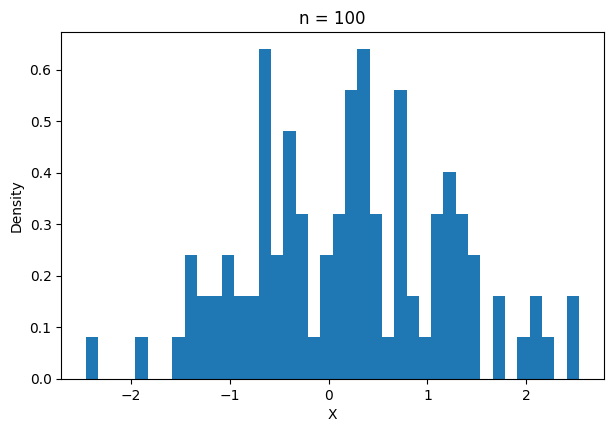

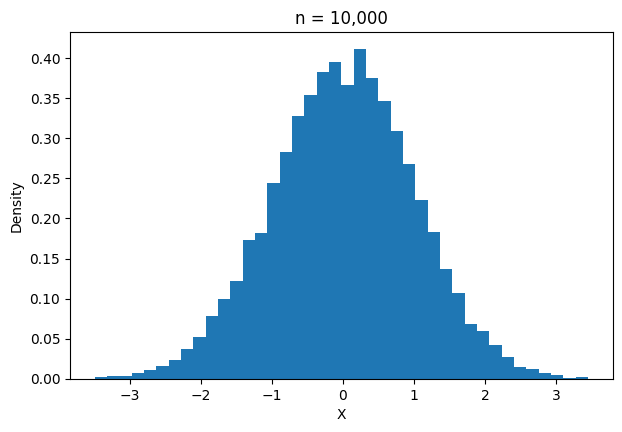

In [3]:
for sample, title in [(sample_100, "n = 100"), (sample_10000, "n = 10,000")]:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.hist(sample, bins=40, density=True)
    ax.set_xlabel("X")
    ax.set_ylabel("Density")
    ax.set_title(title)
    plt.show()

## 随机种子与可复现

In [4]:
rng1 = np.random.default_rng(12345)
rng2 = np.random.default_rng(12345)
a = rng1.normal(size=5)
b = rng2.normal(size=5)
pd.DataFrame({"run_1": a, "run_2": b, "same": a == b})

,run_1,run_2,same
0,-1.423825,-1.423825,True
1,1.263728,1.263728,True
2,-0.870662,-0.870662,True
3,-0.259173,-0.259173,True
4,-0.075343,-0.075343,True


## 用 Monte Carlo 逼近已知答案

若 \(X\sim N(0,1)\)，则 \(E(X^2)=1\)。

In [5]:
B_max = 100000
rng = np.random.default_rng(SEED)
x = rng.normal(size=B_max)
running_mean = np.cumsum(x**2) / np.arange(1, B_max + 1)
checkpoints = [10, 100, 1000, 10000, 100000]
pd.DataFrame({
    "B": checkpoints,
    "MC_estimate": [running_mean[b-1] for b in checkpoints],
    "error": [running_mean[b-1] - 1 for b in checkpoints],
})

,B,MC_estimate,error
0,10,1.073586,0.073586
1,100,1.060885,0.060885
2,1000,1.074883,0.074883
3,10000,0.991805,-0.008195
4,100000,1.000467,0.000467


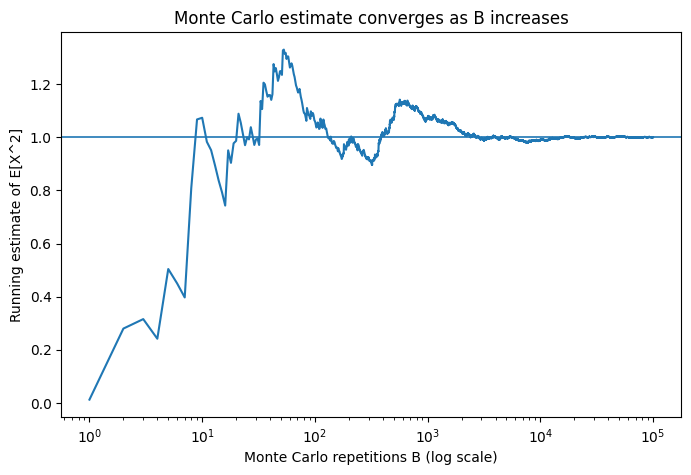

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(np.arange(1, B_max + 1), running_mean)
ax.axhline(1.0, linewidth=1.2)
ax.set_xscale("log")
ax.set_xlabel("Monte Carlo repetitions B (log scale)")
ax.set_ylabel("Running estimate of E[X^2]")
ax.set_title("Monte Carlo estimate converges as B increases")
plt.show()

在后面的计量模拟中，\(n\) 是每次模拟数据集的观测数量，\(B\) 是整个实验重复的次数。

[返回理论正文](../../lectures/monte-carlo.qmd#sec-mc-basics) · [下载 Notebook (ZIP)](../../resources/monte-carlo/downloads/00-monte-carlo-basics.zip)

页面展示交接包已保存的执行结果；渲染不执行代码。